<a href="https://colab.research.google.com/github/jovverse/ANN-DL-LAB/blob/main/ScamSense_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kagglehub tensorflow scikit-learn pandas numpy matplotlib seaborn gradio

In [2]:
import kagglehub
import pandas as pd
import numpy as np
import os

# Download dataset
dataset_path = kagglehub.dataset_download(
    "shivamb/real-or-fake-fake-jobposting-prediction"
)

print("Dataset downloaded successfully!")
print(dataset_path)

# Find CSV file
csv_files = [
    file for file in os.listdir(dataset_path)
    if file.endswith(".csv")
]

print("CSV files:", csv_files)

# Load dataset
df = pd.read_csv(
    os.path.join(dataset_path, csv_files[0])
)

print("Dataset loaded!")
print("Dataset shape:", df.shape)

df.head()

Using Colab cache for faster access to the 'real-or-fake-fake-jobposting-prediction' dataset.
Dataset downloaded successfully!
/kaggle/input/real-or-fake-fake-jobposting-prediction
CSV files: ['fake_job_postings.csv']
Dataset loaded!
Dataset shape: (17880, 18)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [3]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFraud distribution:")
print(df["fraudulent"].value_counts())

print("\nFraud percentages:")
print(
    df["fraudulent"].value_counts(normalize=True) * 100
)

print("\nMissing values:")
print(df.isnull().sum())

Dataset dimensions: (17880, 18)

Column names:
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']

Fraud distribution:
fraudulent
0    17014
1      866
Name: count, dtype: int64

Fraud percentages:
fraudulent
0    95.1566
1     4.8434
Name: proportion, dtype: float64

Missing values:
job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function              

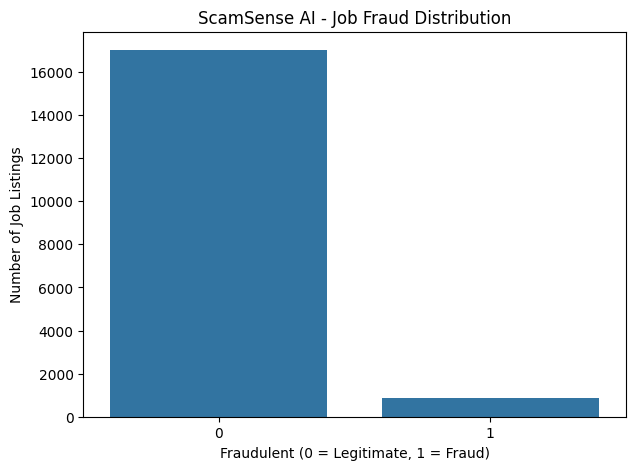

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="fraudulent"
)

plt.title("ScamSense AI - Job Fraud Distribution")
plt.xlabel("Fraudulent (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Job Listings")

plt.show()

In [5]:
# ScamSense AI - Data Cleaning

# Check dataset dimensions
print("Original dataset shape:", df.shape)

# Remove duplicate job postings
df = df.drop_duplicates()

# Fill missing values in text columns
text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

for column in text_columns:
    if column in df.columns:
        df[column] = df[column].fillna("")

# Fill missing values in other relevant columns
for column in ["location", "department", "employment_type",
               "required_experience", "required_education",
               "industry", "function"]:
    if column in df.columns:
        df[column] = df[column].fillna("Unknown")

print("Cleaned dataset shape:", df.shape)

print("\nMissing values in selected columns:")
print(df[text_columns].isnull().sum())

Original dataset shape: (17880, 18)
Cleaned dataset shape: (17880, 18)

Missing values in selected columns:
title              0
company_profile    0
description        0
requirements       0
benefits           0
dtype: int64


In [6]:
# ScamSense AI - Text Feature Engineering

df["job_text"] = (
    df["title"] + " " +
    df["company_profile"] + " " +
    df["description"] + " " +
    df["requirements"] + " " +
    df["benefits"]
)

# Convert text to lowercase
df["job_text"] = df["job_text"].str.lower()

print("Combined job text created!")

print("\nExample job listing:")
print(df["job_text"].iloc[0][:1000])

Combined job text created!

Example job listing:
marketing intern we're food52, and we've created a groundbreaking and award-winning cooking site. we support, connect, and celebrate home cooks, and give them everything they need in one place.we have a top editorial, business, and engineering team. we're focused on using technology to find new and better ways to connect people around their specific food interests, and to offer them superb, highly curated information about food and cooking. we attract the most talented home cooks and contributors in the country; we also publish well-known professionals like mario batali, gwyneth paltrow, and danny meyer. and we have partnerships with whole foods market and random house.food52 has been named the best food website by the james beard foundation and iacp, and has been featured in the new york times, npr, pando daily, techcrunch, and on the today show.we're located in chelsea, in new york city. food52, a fast-growing, james beard award-winnin

In [7]:
# Input features
X = df["job_text"]

# Target variable
y = df["fraudulent"].astype(int)

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget labels:")
print(y.value_counts())

Input shape: (17880,)
Target shape: (17880,)

Target labels:
fraudulent
0    17014
1      866
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining fraud distribution:")
print(y_train.value_counts())

Training samples: 14304
Testing samples: 3576

Training fraud distribution:
fraudulent
0    13611
1      693
Name: count, dtype: int64


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert text into numerical features
tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (14304, 10000)
Testing TF-IDF shape: (3576, 10000)


In [10]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

# Build ScamSense AI ANN
model = Sequential([
    Input(shape=(X_train_tfidf.shape[1],)),

    Dense(256, activation="relu"),
    Dropout(0.4),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(64, activation="relu"),

    Dense(1, activation="sigmoid")
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     2,560,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,601,473 (9.92 MB)

 Trainable params: 2,601,473 (9.92 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Calculate class weights
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

# Early stopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train_tfidf,
    y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.2,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

Class weights: {np.int64(0): np.float64(0.5254573506722504), np.int64(1): np.float64(10.32034632034632)}
Epoch 1/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 9s 56ms/step - accuracy: 0.8999 - auc: 0.9236 - loss: 0.3748 - precision: 0.3012 - recall: 0.7929 - val_accuracy: 0.9409 - val_auc: 0.9759 - val_loss: 0.1639 - val_precision: 0.4323 - val_recall: 0.8647
Epoch 2/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 8s 88ms/step - accuracy: 0.9707 - auc: 0.9947 - loss: 0.0856 - precision: 0.6316 - recall: 0.9643 - val_accuracy: 0.9671 - val_auc: 0.9773 - val_loss: 0.0976 - val_precision: 0.6089 - val_recall: 0.8195
Epoch 3/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 8s 64ms/step - accuracy: 0.9916 - auc: 0.9983 - loss: 0.0303 - precision: 0.8591 - recall: 0.9911 - val_accuracy: 0.9752 - val_auc: 0.9621 - val_loss: 0.0884 - val_precision: 0.7039 - val_recall: 0.8045
Epoch 4/15
90/90 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - accuracy: 0.9968 - auc: 0.9997 - loss: 0.0120 - precision: 0.9395 - recall: 0.9982 - val_accuracy: 0.9773 - val_auc: 0.

In [12]:
# Evaluate ANN on unseen test data
results = model.evaluate(
    X_test_tfidf,
    y_test,
    verbose=0
)

print("ScamSense AI Test Results")

for name, value in zip(model.metrics_names, results):
    print(f"{name}: {value:.4f}")

ScamSense AI Test Results
loss: 0.0643
compile_metrics: 0.9793


112/112 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step
SCAMSENSE AI CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate     0.9911    0.9871    0.9891      3403
  Fraudulent     0.7647    0.8266    0.7944       173

    accuracy                         0.9793      3576
   macro avg     0.8779    0.9068    0.8918      3576
weighted avg     0.9802    0.9793    0.9797      3576

ROC-AUC: 0.9852204532213161
Average Precision: 0.8910592639227367


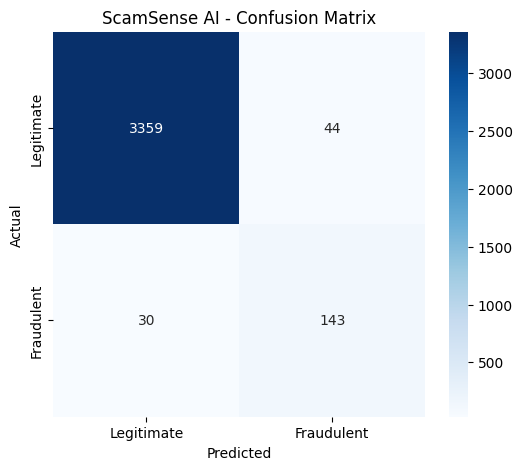

In [13]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Get fraud probabilities
y_prob = model.predict(X_test_tfidf).ravel()

# Convert probabilities into predictions
y_pred = (y_prob >= 0.5).astype(int)

# Classification report
print("SCAMSENSE AI CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraudulent"],
    digits=4
))

# ROC-AUC
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

# Precision-recall AUC
print(
    "Average Precision:",
    average_precision_score(y_test, y_prob)
)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ScamSense AI - Confusion Matrix")
plt.show()

In [14]:
model.save("ScamSense_ANN.keras")

import joblib

joblib.dump(tfidf, "ScamSense_TFIDF.pkl")

print("ANN model and TF-IDF vectorizer saved successfully!")

ANN model and TF-IDF vectorizer saved successfully!


In [15]:
!pip install -q gradio

In [22]:
from sklearn.metrics.pairwise import cosine_similarity
import re

def resume_job_match(resume_text, job_text):

    if not resume_text or not job_text:
        return 0, [], [], "Please provide both resume and job description."

    # Transform resume and job description using existing TF-IDF
    resume_vector = tfidf.transform([resume_text])
    job_vector = tfidf.transform([job_text])

    # Calculate cosine similarity
    similarity = cosine_similarity(
        resume_vector,
        job_vector
    )[0][0]

    match_percentage = round(similarity * 100, 2)

    # Extract meaningful words
    resume_words = set(re.findall(r'\b[a-zA-Z]{3,}\b', resume_text.lower()))
    job_words = set(re.findall(r'\b[a-zA-Z]{3,}\b', job_text.lower()))

    # Remove common English words
    common_words = {
        "the", "and", "for", "with", "from", "this",
        "that", "you", "are", "was", "will", "have",
        "has", "our", "your", "their", "they", "job"
    }

    resume_words -= common_words
    job_words -= common_words

    matching_words = sorted(resume_words & job_words)
    missing_words = sorted(job_words - resume_words)

    if match_percentage >= 70:
        compatibility = "Strong Match"
    elif match_percentage >= 40:
        compatibility = "Moderate Match"
    else:
        compatibility = "Low Match"

    return (
        match_percentage,
        matching_words[:15],
        missing_words[:15],
        compatibility
    )


print("Resume matching module created successfully!")

Resume matching module created successfully!


In [24]:
sample_resume = """
Data Science student with experience in Python, SQL,
Machine Learning, Artificial Intelligence, Pandas,
TensorFlow, data analysis and data visualization.
"""

sample_job = """
We are hiring a Data Scientist with skills in Python,
SQL, Machine Learning, Artificial Intelligence,
TensorFlow, data analysis and statistical modelling.
"""

result = resume_job_match(
    sample_resume,
    sample_job
)

print("Resume Match:", result[0], "%")
print("Matching Skills:", result[1])
print("Missing Skills:", result[2])
print("Compatibility:", result[3])

Resume Match: 53.99 %
Matching Skills: ['analysis', 'artificial', 'data', 'intelligence', 'learning', 'machine', 'python', 'sql', 'tensorflow']
Missing Skills: ['hiring', 'modelling', 'scientist', 'skills', 'statistical']
Compatibility: Moderate Match


In [27]:
!pip install -q pypdf python-docx

In [28]:
from pypdf import PdfReader
from docx import Document
import os

def extract_resume_text(file_path):

    if file_path is None:
        return ""

    extension = os.path.splitext(file_path)[1].lower()

    # PDF resume
    if extension == ".pdf":
        reader = PdfReader(file_path)

        text = ""
        for page in reader.pages:
            text += page.extract_text() or ""

        return text

    # Word resume
    elif extension == ".docx":
        document = Document(file_path)

        text = "\n".join(
            paragraph.text for paragraph in document.paragraphs
        )

        return text

    return ""

In [42]:
custom_css = """
@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&display=swap');

html, body {
    margin: 0 !important;
    padding: 0 !important;
    background: #070A12 !important;
    font-family: 'Inter', sans-serif !important;
}

.gradio-container {
    width: 100% !important;
    max-width: 100% !important;
    margin: 0 !important;
    padding: 20px 35px !important;
    box-sizing: border-box !important;
    background: #070A12 !important;
}

/* Remove narrow centered layout */
.main {
    width: 100% !important;
    max-width: 100% !important;
}

/* Full-width header */
#hero {
    width: 100% !important;
    box-sizing: border-box !important;
    background: linear-gradient(110deg, #0D1324, #101A32);
    border: 1px solid #202D49;
    border-radius: 12px;
    padding: 30px 40px;
    margin-bottom: 25px;
}

#hero h1 {
    font-size: 42px;
    font-weight: 800;
    color: #F7F9FC;
    margin: 12px 0;
}

#hero h1 span {
    color: #5AC8FA;
}

.brand-label {
    color: #5AC8FA;
    font-size: 11px;
    letter-spacing: 2.5px;
    font-weight: 700;
}

#hero p {
    color: #9AA8C2;
    font-size: 15px;
}

.header-meta {
    border-top: 1px solid #26334D;
    padding-top: 15px;
    margin-top: 20px;
    color: #71819E;
    font-size: 11px;
    letter-spacing: 1px;
}

/* Force horizontal layout on desktop */
@media screen and (min-width: 900px) {
    .gradio-container .row {
        display: flex !important;
        flex-direction: row !important;
        flex-wrap: nowrap !important;
        align-items: stretch !important;
        width: 100% !important;
        gap: 25px !important;
    }

    .gradio-container .row > .column {
        min-width: 0 !important;
        flex: 1 1 50% !important;
    }
}

/* Input and result panels */
.input-panel,
.result-card {
    background: #0D1220 !important;
    border: 1px solid #202D49 !important;
    border-radius: 12px !important;
    padding: 25px !important;
    box-sizing: border-box !important;
    width: 100% !important;
}

textarea,
input {
    background: #080D18 !important;
    border: 1px solid #26334D !important;
    color: #E8ECF5 !important;
    border-radius: 8px !important;
}

.analyze-btn {
    background: #2563EB !important;
    color: white !important;
    border: none !important;
    border-radius: 7px !important;
    height: 48px !important;
    font-weight: 600 !important;
}

.analyze-btn:hover {
    background: #3478F6 !important;
}

.result-card {
    color: #E8ECF5 !important;
    min-height: 450px !important;
}

.status-label {
    color: #5AC8FA;
    font-size: 10px;
    letter-spacing: 2px;
    font-weight: 700;
}

.score-track {
    height: 8px;
    background: #202D49;
    border-radius: 20px;
    overflow: hidden;
    margin-top: 15px;
}

.score-fill {
    height: 100%;
    border-radius: 20px;
}

.warning-tag,
.skill-tag,
.missing-tag {
    display: inline-block;
    border-radius: 5px;
    padding: 7px 10px;
    margin: 4px;
    font-size: 12px;
}

.warning-tag,
.missing-tag {
    background: #251522;
    border: 1px solid #553044;
    color: #F08BB4;
}

.skill-tag {
    background: #10251F;
    border: 1px solid #20503F;
    color: #42D6B3;
}

.disclaimer {
    margin-top: 20px;
    background: #111827;
    border: 1px solid #26334D;
    border-radius: 7px;
    padding: 13px;
    font-size: 11px;
    color: #8998B2;
}

footer {
    display: none !important;
}

/* Mobile fallback */
@media screen and (max-width: 899px) {
    .gradio-container {
        padding: 12px !important;
    }

    .gradio-container .row {
        flex-direction: column !important;
        flex-wrap: wrap !important;
    }
}
"""

In [43]:
with gr.Blocks(
    css=custom_css,
    theme=gr.themes.Base(
        primary_hue="blue",
        secondary_hue="cyan",
        neutral_hue="slate"
    )
) as demo:

    gr.HTML("""
    <div id="hero">
        <div class="brand-label">
            ARTIFICIAL INTELLIGENCE · RECRUITMENT SECURITY
        </div>
        <h1>ScamSense <span>AI</span></h1>
        <p>
            Recruitment fraud detection and resume compatibility analysis.
        </p>
        <div class="header-meta">
            ANN FRAUD DETECTION | NLP | RESUME MATCHING
        </div>
    </div>
    """)

    with gr.Tabs():

        # =====================================
        # JOB FRAUD DETECTION
        # =====================================

        with gr.Tab("Job Fraud Detection"):

            gr.HTML("""
            <h2>Job Listing Analysis</h2>
            <p>Screen job postings for potential recruitment fraud.</p>
            """)

            with gr.Row(equal_height=True):

                with gr.Column(scale=1, min_width=400):

                    fraud_job_input = gr.Textbox(
                        label="Job Description",
                        placeholder="Paste the job title, company details, salary and description...",
                        lines=16
                    )

                    fraud_button = gr.Button(
                        "Run Fraud Analysis",
                        elem_classes="analyze-btn"
                    )

                with gr.Column(scale=1, min_width=400):

                    fraud_output = gr.HTML("""
                    <div class="result-card">
                        <h2>Analysis Report</h2>
                        <p>Your prediction will appear here.</p>
                    </div>
                    """)

            fraud_button.click(
                fn=analyze_job,
                inputs=fraud_job_input,
                outputs=fraud_output
            )

        # =====================================
        # RESUME JOB MATCH
        # =====================================

        with gr.Tab("Resume–Job Match"):

            gr.HTML("""
            <h2>Resume Compatibility</h2>
            <p>Compare your resume with a job description.</p>
            """)

            with gr.Row(equal_height=True):

                with gr.Column(scale=1, min_width=400):

                    resume_file = gr.File(
                        label="Upload Resume (PDF or DOCX)",
                        file_types=[".pdf", ".docx"],
                        type="filepath"
                    )

                    extract_button = gr.Button(
                        "Extract Resume Text"
                    )

                    resume_preview = gr.Textbox(
                        label="Resume Text",
                        lines=8
                    )

                    match_job_input = gr.Textbox(
                        label="Job Description",
                        placeholder="Paste the job description...",
                        lines=8
                    )

                    match_button = gr.Button(
                        "Analyse Resume Match",
                        elem_classes="analyze-btn"
                    )

                with gr.Column(scale=1, min_width=400):

                    match_output = gr.HTML("""
                    <div class="result-card">
                        <h2>Compatibility Report</h2>
                        <p>Upload your resume to begin.</p>
                    </div>
                    """)

            extract_button.click(
                fn=extract_resume_text,
                inputs=resume_file,
                outputs=resume_preview
            )

            match_button.click(
                fn=match_resume,
                inputs=[resume_preview, match_job_input],
                outputs=match_output
            )

demo.launch(share=True)

/tmp/ipykernel_3601/3084843797.py:1: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://100cf1b8efd0290246.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
